In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("retail_sales_dataset[1].csv")

In [3]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
#Question: How many rows and columns are present in the complete dataset?
df.shape

(1000, 9)

In [5]:
"""Are there any missing values in the dataset? If yes, 
how many missing values are present in each column?"""
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [6]:
#What data type does each column have?
df.dtypes

Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

In [7]:
"""How can you convert the Date column from object 
to a proper datetime data type using Pandas?"""
df["Date"] = pd.to_datetime(df["Date"])
print(df["Date"].dtype)

datetime64[ns]


In [8]:
#Does your dataset contain any duplicate rows?
df.duplicated().sum()

np.int64(0)

In [9]:
"""What are the basic statistics for the numerical columns, such as age, quantity, 
price per unit, and total amount?"""
df.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000256,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [10]:
#What is the total revenue generated by all 1,000 transactions?
df["Total Amount"].sum()

np.int64(456000)

In [11]:
#What is the average amount spent per transaction?
df["Total Amount"].mean()

np.float64(456.0)

In [12]:
"""Calculate the total quantity of products sold using the Quantity column. 
Which Pandas method will you use?"""
df["Quantity"].sum()

np.int64(2514)

In [13]:
#Now calculate the total revenue for each product category.
df.groupby("Product Category")["Total Amount"].sum()

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

In [14]:
#Find the highest-revenue category
df.groupby("Product Category")["Total Amount"].sum().idxmax()

'Electronics'

In [15]:
#Revenue by Gender
df.groupby("Gender")["Total Amount"].sum()

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

In [16]:
#Monthly Sales Analysis
df.groupby(df["Date"].dt.month) ["Total Amount"].sum()

Date
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64

In [17]:
#Find the month with the highest revenue
df.groupby(df["Date"].dt.month) ["Total Amount"].sum().idxmax()

np.int32(5)

In [18]:
#Sales Visualization
import matplotlib.pyplot as plt

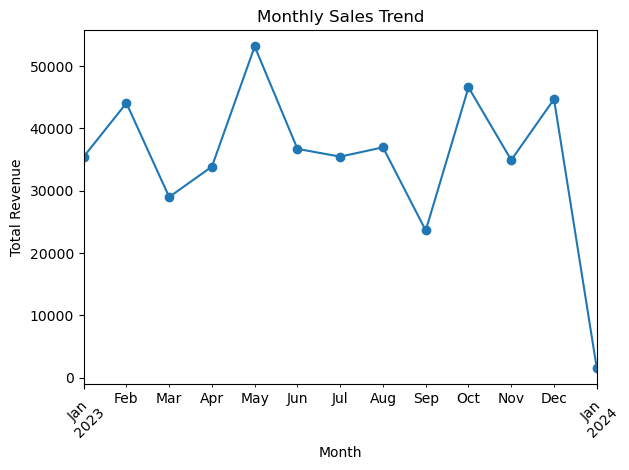

In [19]:
#Monthly Sales Trend
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum()

monthly_sales.plot(kind="line", marker="o")

plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.title("Monthly Sales Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
#Find the lowest-revenue month
df.groupby(df["Date"].dt.month) ["Total Amount"].sum().idxmin()

np.int32(9)

In [21]:
#Calculate average revenue by product category
df.groupby("Product Category")["Total Amount"].mean()

Product Category
Beauty         467.475570
Clothing       443.247863
Electronics    458.786550
Name: Total Amount, dtype: float64

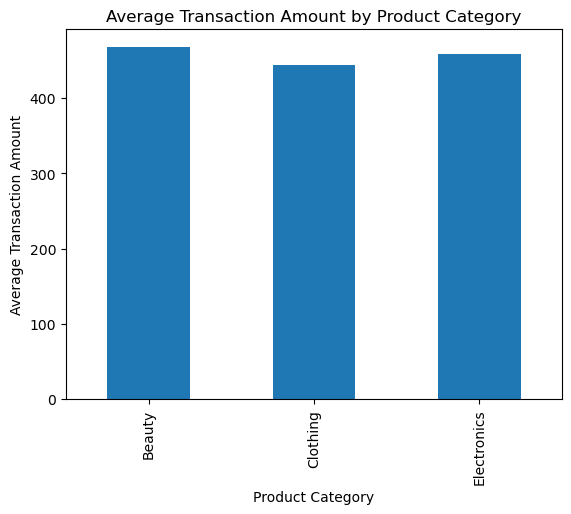

In [22]:
#create a bar chart showing the average transaction amount by product category.
category_avg = df.groupby("Product Category")["Total Amount"].mean()
category_avg.plot(kind="bar")
plt.xlabel("Product Category")
plt.ylabel("Average Transaction Amount")
plt.title("Average Transaction Amount by Product Category")
plt.show()

In [23]:
#Find the product category with the highest average transaction amount.
df.groupby("Product Category")["Total Amount"].mean().idxmax()

'Beauty'

## Business Insights

1. **Highest Revenue Category:** Electronics generated the highest total revenue of 156,905.
2. **Highest Average Transaction Amount:** Beauty had the highest average transaction amount of 467.48.
3. **Highest Revenue Month:** May recorded the highest monthly revenue of 53,150.